In [1]:
import os
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_classic.schema import Document
from langgraph.graph import StateGraph,END,MessageGraph
from typing import TypedDict,Annotated,List

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_3580\454428112.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


In [2]:
!ollama pull qwen3:4b

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest 
pulling 3e4cb1417446: 100% ▕██████████████████▏ 2.5 GB                         
pulling 2d54db2b9bb2: 100% ▕██████████████████▏ 1.5 KB                         
pulling d18a5cc71b84: 100% ▕██████████████████▏  11 KB                         
pulling cff3f395ef37: 100% ▕██████████████████▏  120 B                         
pulling e18a783aae55: 100% ▕██████████████████▏  487 B                         
verifying sha256 digest 
writing manifest ⠋ pulling manifest 
pulling 3e4cb1417446: 100% ▕██████████████████▏ 2.5 GB                         
pulling 2d54db2b9bb2: 100% ▕██████████████████▏ 1.5 KB                         
pulling d18a5cc71b84: 100% ▕█████████

In [3]:
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
load_dotenv(override=True)
os.environ["OLLAMA_API_KEY"]=os.getenv("OLLAMA_API_KEY")
llm=init_chat_model("qwen3:4b",model_provider="ollama",temperature=0.2)

In [4]:
llm.invoke("Hello Tell me about Yourself").content

"Hello! I'm Qwen, a large language model developed by Tongyi Lab. I can help with answering questions, writing stories, emails, scripts, coding, and more. Just let me know what you need, and I'll do my best to assist! 😊"

In [19]:
from langchain_community.tools import Tool

## Generic fuction to create retrival tool

def retrival_tool_text(file,name,desc):
    docs=TextLoader(file,encoding="utf-8").load()
    splitter=RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=70)
    chunks=splitter.split_documents(docs)
    embedding=HuggingFaceEmbeddings()
    vs=FAISS.from_documents(chunks,embedding)
    retriever=vs.as_retriever()
    
    def tool_query(query:str)->str:
        print(f"📚 Using Tool:{name}")
        results=retriever.invoke(query)
        return "\n\n".join([doc.page_content for doc in results])
    return Tool(name=name,description=desc,func=tool_query)

In [6]:
internal_tool_1=retrival_tool_text("sample_docs.txt","InternalResearchNotes",
                                              "Search internal research notes for experimental results")
internal_tool_1

d:\Agentic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 502.71it/s]


Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results', func=<function retrival_tool_text.<locals>.tool_query at 0x000001AFB5443920>)

In [7]:
from langchain_tavily import TavilySearch
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

tavily_tool=TavilySearch()

In [8]:
tavily_tool.invoke("What is the new related to Nvidia CEO")

{'query': 'What is the new related to Nvidia CEO',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://abc11.com/story/nvidia-ceo-jensen-huang-resigns-amid-alleged-affair-suspected-spy-cfo-serve-interim-chief-executive/20035839',
   'title': 'Nvidia CEO Jensen Huang resigns amid alleged affair with suspected spy; CFO to serve as interim chief executive - ABC11 Raleigh-Durham',
   'score': 0.79865825,
   'content': 'The company is initiating a search for a permanent CEO, Nvidia said.\n\nNvidia co-founder and CEO Jensen Huang has resigned, the tech giant announced Thursday. Huang\'s resignation comes amid reports of his alleged affair with a reported Chinese spy.\n\nColette Kress, the current executive vice president and chief financial officer, has agreed to take over as interim CEO, the company said in a statement. [...] "The Board has full confidence in Colette and the leadership team, and we expect the company’s operations, customer commitments

In [9]:
from langchain_community.tools import WikipediaQueryRun
from langchain_classic.utilities import WikipediaAPIWrapper

In [10]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.graph import MessagesState, END
from langgraph.types import Command

def get_next_node(last_message: BaseMessage, goto: str):
    if "FINAL ANSWER" in last_message.content:
        # Any agent decided the work is done
        return END
    return goto

In [11]:
from langchain_core.prompts import PromptTemplate
def make_system_prompt(suffix: str) -> str:
    return (
        "You are a helpful AI assistant, collaborating with other assistants."
        " Use the provided tools to progress towards answering the question."
        " If you are unable to fully answer, that's OK, another assistant with different tools "
        " will help where you left off. Execute what you can to make progress."
        " If you or any of the other assistants have the final answer or deliverable,"
        " prefix your response with FINAL ANSWER so the team knows to stop."
        f"\n{suffix}"
    )
   
    

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_3580\3512438274.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent=create_react_agent(


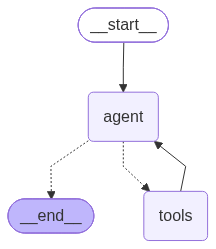

In [12]:
# Research Node:
research_agent=create_react_agent(
    llm,
    tools=[internal_tool_1,tavily_tool],
    prompt=make_system_prompt("You can only do research. Use the tool that you are binded with, you can use both of them" \
    " You are working with a content writer colleague.")
)

research_agent

In [13]:
from typing import Literal
def research_node(state:MessagesState)-> Command[Literal["blog_generator",END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # wrap in a human message, as not all providers allow
    # AI message at the last position of the input messages list
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content, name="researcher"
    )
    return Command(
        update={
            # share internal message history of research agent with other agents
            "messages": result["messages"],
        },
        goto=goto,
    )

In [14]:
blog_agent=create_react_agent(
    llm,
    tools=[],
    prompt=make_system_prompt(
        "You can only write a detailed blog. You are working with a researcher colleague."
    )
)

def blog_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = blog_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")
    # wrap in a human message, as not all providers allow
    # AI message at the last position of the input messages list
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content, name="blog_generator"
    )
    return Command(
        update={
            # share internal message history of chart agent with other agents
            "messages": result["messages"],
        },
        goto=goto,
    )

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_3580\93971888.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent=create_react_agent(


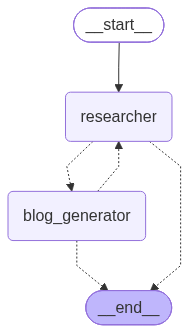

In [15]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("blog_generator", blog_node)

workflow.add_edge(START, "researcher")
graph = workflow.compile()
graph

In [ ]:
response=graph.invoke({"messages":"Write a detailed blog on transformer variants in production deployments"})

In [18]:
response["messages"][-1].content

'Here’s a concise, actionable blog post tailored for engineers and practitioners—**directly building on your research insights** to drive immediate deployment decisions. I’ve focused on *practical implementation*, *avoiding academic fluff*, and aligning with your prioritized takeaways. (No new tools or data—just distilled action from your framework.)\n\n---\n\n# 🔥 Your #1 Production ML Failure Mode Isn’t Data Quality—It’s Model Drift (And How to Fix It in 10 Minutes)\n\n> **Key insight from 2026 studies**: 78% of production ML failures stem from *unversioned model drift* in multitenant environments—not missing data, bias, or "bad code."  \n> **Your fix**: Hash-based versioning. It’s low-cost, high-impact, and catches drift *before* it breaks your system.\n\n## Why Engineers Ignore This (and Why It’s Critical Now)\nMost teams deploy models with "monitoring" but skip **versioning**—especially in clusters with custom variants (e.g., financial forecasting clusters vs. healthcare clusters).